# Predicting 30-Day Hospital Readmission in Diabetic Patients: Traditional ML vs. Deep Learning

**Course:** Machine Learning, Summative Project  |  **Author:** _your name_

| Resource | Link |
|---|---|
| GitHub repository | _add link_ |
| Google Drive (raw data + saved models) | _add link_ |
| Presentation video | _add link_ |

**Dataset:** Diabetes 130-US Hospitals for Years 1999-2008, UCI Machine Learning Repository (Strack et al., 2014). About 101k inpatient encounters. Verify the row count, license and citation on the UCI page before submitting.

**Task:** 3-class classification of `readmitted` (`NO`, `>30` days, `<30` days), followed by a binary follow-up (`<30` vs. rest).

**Notebook map**

1. Setup and reproducibility
2. Data loading and EDA
3. Cleaning and feature engineering
4. Patient-grouped train/validation/test split
5. Experiments on leakage and feature engineering
6. Traditional ML (Scikit-Learn)
7. Deep learning (TensorFlow/Keras + `tf.data`)
8. Evaluation: learning curves, confusion matrices, ROC/PR, final comparison
9. Binary follow-up (`<30` vs. rest)
10. Error analysis and fairness
11. Saving artifacts

## 1. Setup and reproducibility

All randomness is controlled through a single `SEED`. The config cell below holds the switches you may want to change. Runtime-heavy options (the SVM subsample size and the number of deep-learning trials) are exposed there so you can scale the run to your machine.

In [ ]:
import os, random, warnings, urllib.request, zipfile, io
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, recall_score, precision_score, roc_auc_score,
                             roc_curve, auc, log_loss, precision_recall_curve, average_precision_score,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.model_selection import (StratifiedGroupKFold, RandomizedSearchCV, ParameterSampler,
                                     learning_curve, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.svm import SVC
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)

SEED = 42
random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)

# ---- configuration -------------------------------------------------------
DATA_DIR  = Path("data")      # raw data lives here (NOT committed to GitHub)
MODEL_DIR = Path("models")
FIG_DIR   = Path("figures")
for p in (DATA_DIR, MODEL_DIR, FIG_DIR):
    p.mkdir(exist_ok=True)

KEEP_FIRST_ENCOUNTER_ONLY = False   # True reproduces Strack et al. (one encounter per patient, ~70k rows)
SVM_SUBSAMPLE   = 15000             # RBF-SVM scales poorly, so it is trained on a subsample of the training set
N_DL_TRIALS     = 8                 # random-search trials per Keras architecture
N_ML_SEARCH_ITER = 12               # random-search iterations per sklearn model

CLASS_NAMES = ["NO", ">30", "<30"]
TARGET_MAP  = {"NO": 0, ">30": 1, "<30": 2}

print("TensorFlow", tf.__version__, "| GPUs:", len(tf.config.list_physical_devices("GPU")))

TensorFlow 2.21.0 | GPUs: 1


## 2. Data loading and exploratory analysis

The UCI archive provides `diabetic_data.csv` (the encounters) and `IDS_mapping.csv` (look-ups for admission type, discharge disposition and admission source). The cell below downloads and unzips them automatically. If the download fails (for example, no internet access), download the zip manually from the UCI page, or from your Drive folder, and extract it into `data/`.

Missing values are encoded as `"?"` in this file. We read with `keep_default_na=False` so that only `"?"` is treated as missing. Otherwise pandas would silently turn the legitimate category `"None"` (lab test not performed) in `A1Cresult` and `max_glu_serum` into NaN.

In [ ]:
UCI_URL = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"

def download_data():
    if (DATA_DIR / "diabetic_data.csv").exists():
        return
    print("Downloading from UCI ...")
    with urllib.request.urlopen(UCI_URL) as r:
        zipfile.ZipFile(io.BytesIO(r.read())).extractall(DATA_DIR)
    print("Extracted:", [p.name for p in DATA_DIR.iterdir()])

download_data()
raw = pd.read_csv(DATA_DIR / "diabetic_data.csv", na_values=["?"], keep_default_na=False)
print("Raw shape:", raw.shape)
assert len(raw) >= 20_000, "Dataset must have >= 20,000 raw rows"
raw.head()

Extracted: ['IDS_mapping.csv', 'diabetic_data.csv']
Raw shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [ ]:
print(raw.dtypes.value_counts(), "\n")
miss = raw.isna().mean().mul(100).sort_values(ascending=False)
print("Columns with missing values (%):")
print(miss[miss > 0].round(1))

print("\nTarget distribution:")
print(raw["readmitted"].value_counts().rename("count").to_frame().join(
      raw["readmitted"].value_counts(normalize=True).rename("share").round(3)))

per_patient = raw.groupby("patient_nbr").size()
print(f"\nUnique patients: {per_patient.shape[0]:,} for {len(raw):,} encounters "
      f"({(per_patient > 1).mean():.1%} of patients appear more than once; max {per_patient.max()} encounters)")

object    37
int64     13
Name: count, dtype: int64 

Columns with missing values (%):
weight               96.9
medical_specialty    49.1
payer_code           39.6
race                  2.2
diag_3                1.4
diag_2                0.4
diag_1                0.0
dtype: float64

Target distribution:
            count  share
readmitted              
NO          54864  0.539
>30         35545  0.349
<30         11357  0.112

Unique patients: 71,518 for 101,766 encounters (23.5% of patients appear more than once; max 40 encounters)


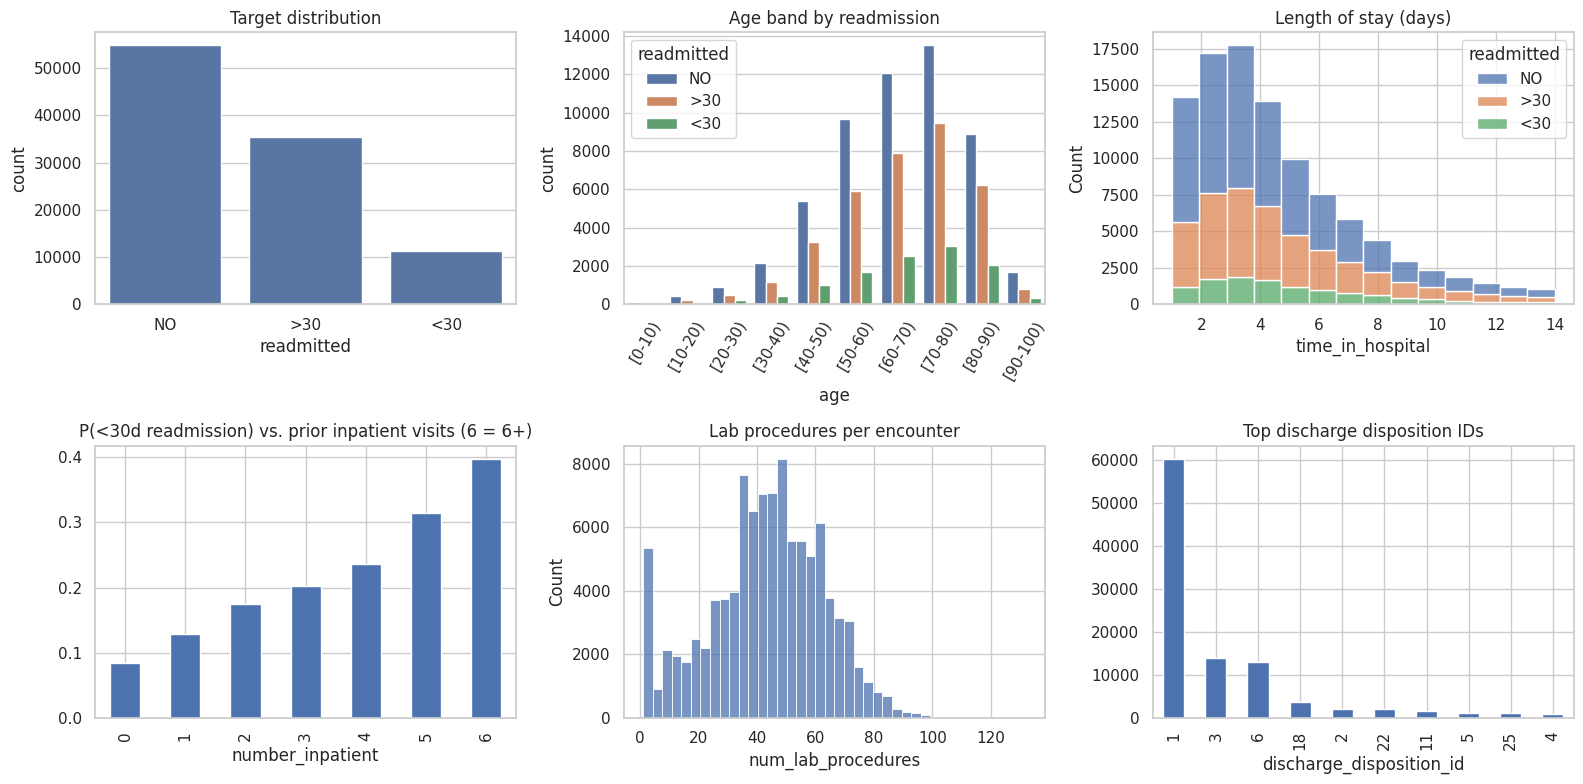

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
order = ["NO", ">30", "<30"]

sns.countplot(data=raw, x="readmitted", order=order, ax=axes[0, 0]); axes[0, 0].set_title("Target distribution")
sns.countplot(data=raw, x="age", hue="readmitted", hue_order=order, ax=axes[0, 1])
axes[0, 1].set_title("Age band by readmission"); axes[0, 1].tick_params(axis="x", rotation=60)
sns.histplot(data=raw, x="time_in_hospital", hue="readmitted", hue_order=order, multiple="stack", bins=14, ax=axes[0, 2])
axes[0, 2].set_title("Length of stay (days)")

rate = raw.assign(lt30=(raw["readmitted"] == "<30")).groupby(raw["number_inpatient"].clip(upper=6))["lt30"].mean()
rate.plot(kind="bar", ax=axes[1, 0]); axes[1, 0].set_title("P(<30d readmission) vs. prior inpatient visits (6 = 6+)")

sns.histplot(raw["num_lab_procedures"], bins=40, ax=axes[1, 1]); axes[1, 1].set_title("Lab procedures per encounter")
raw["discharge_disposition_id"].value_counts().head(10).plot(kind="bar", ax=axes[1, 2])
axes[1, 2].set_title("Top discharge disposition IDs")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_overview.png", dpi=150); plt.show()

**Interpretation (write your own after running):** comment on (i) the class imbalance, especially the share of `<30`; (ii) which columns are mostly empty (`weight`, `medical_specialty`, `payer_code`) and what that implies; (iii) the number of patients with multiple encounters, which motivates the grouped split in Section 4; (iv) the relationship between prior inpatient visits and readmission.

## 3. Cleaning and feature engineering

**Cleaning decisions (each should appear in your report's Methodology):**

* Drop `weight` (about 97% missing), `examide` and `citoglipton` (constant), and the ID columns `encounter_id` and `patient_nbr`. `patient_nbr` is kept separately as the grouping key for splitting.
* Remove encounters whose discharge disposition is *expired* or *hospice* (IDs 11, 13, 14, 19, 20, 21), because those patients cannot be readmitted. Keeping them would let models learn a trivially "safe" group and misstate real-world performance.
* Remove the handful of rows with `gender == "Unknown/Invalid"`.
* Missing `race`, `payer_code` and `medical_specialty` become an explicit `Unknown` category. Missingness itself may be informative, and imputing a clinical category would be fabricating data.

**Engineered features:**

| Feature | Rationale |
|---|---|
| `diag_{1,2,3}_group` | ICD-9 codes grouped into clinical categories (Strack et al.), which reduces about 700 codes to 9 groups |
| `diag_{1,2,3}_code` | 3-character ICD-9 prefix, used by the Keras embedding branch only |
| `n_meds_active`, `n_meds_changed` | Medication burden and treatment instability across the drug columns |
| `total_prior_visits`, `emerg_inpatient_prior` | Prior utilisation is the strongest known readmission signal |
| `labs_per_day`, `meds_per_day` | Intensity of care normalised by length of stay |
| `a1c_tested`, `glucose_tested` | Whether monitoring was performed (the core hypothesis of the source paper) |
| `age_mid` | Numeric midpoint of the age band |
| `medical_specialty` | Top 15 specialties kept, rest grouped as `Other` |

The "rare drug" filter and the specialty grouping use full-data frequencies. These are unsupervised and target-free, so the leakage risk is negligible, but state this in the report.

In [ ]:
EXPIRED_HOSPICE_IDS = [11, 13, 14, 19, 20, 21]
DROP_COLS = ["weight", "examide", "citoglipton"]
DRUG_COLS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide",
             "glipizide", "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol",
             "troglitazone", "tolazamide", "examide", "citoglipton", "insulin", "glyburide-metformin",
             "glipizide-metformin", "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone"]
ID_COLS = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]
CODE_COLS = ["diag_1_code", "diag_2_code", "diag_3_code"]

def icd9_group(code):
    # Grouping follows Strack et al. (2014), Table 2
    if pd.isna(code): return "Missing"
    c = str(code)
    if c.startswith(("V", "E")): return "Other"
    try: v = float(c)
    except ValueError: return "Other"
    if 250 <= v < 251: return "Diabetes"
    if 390 <= v <= 459 or v == 785: return "Circulatory"
    if 460 <= v <= 519 or v == 786: return "Respiratory"
    if 520 <= v <= 579 or v == 787: return "Digestive"
    if 800 <= v <= 999: return "Injury"
    if 710 <= v <= 739: return "Musculoskeletal"
    if 580 <= v <= 629 or v == 788: return "Genitourinary"
    if 140 <= v <= 239: return "Neoplasms"
    return "Other"

def icd9_code3(code):
    return "Missing" if pd.isna(code) else str(code).split(".")[0]

def clean(df):
    d = df.copy()
    n0 = len(d)
    d = d[~d["discharge_disposition_id"].isin(EXPIRED_HOSPICE_IDS)]
    d = d[d["gender"].isin(["Male", "Female"])]
    if KEEP_FIRST_ENCOUNTER_ONLY:
        d = d.sort_values("encounter_id").drop_duplicates("patient_nbr", keep="first")
    print(f"Cleaning removed {n0 - len(d):,} rows ({n0:,} -> {len(d):,})")
    return d.reset_index(drop=True)

def engineer(d):
    d = d.copy()
    y = d["readmitted"].map(TARGET_MAP).values
    groups = d["patient_nbr"].values
    meta = d[["age", "race", "gender"]].copy()
    meta["race"] = meta["race"].fillna("Unknown")

    d = d.drop(columns=["encounter_id", "patient_nbr", "readmitted"] + [c for c in DROP_COLS if c in d.columns])

    # age
    d["age_mid"] = d["age"].str.extract(r"\[(\d+)-(\d+)\)").astype(float).mean(axis=1)
    d = d.drop(columns=["age"])

    # diagnoses
    for i in (1, 2, 3):
        d[f"diag_{i}_group"] = d[f"diag_{i}"].map(icd9_group)
        d[f"diag_{i}_code"] = d[f"diag_{i}"].map(icd9_code3)
    d = d.drop(columns=["diag_1", "diag_2", "diag_3"])

    # medications
    drug_cols = [c for c in DRUG_COLS if c in d.columns]
    d["n_meds_active"] = (d[drug_cols] != "No").sum(axis=1)
    d["n_meds_changed"] = d[drug_cols].isin(["Up", "Down"]).sum(axis=1)
    rare = [c for c in drug_cols if (d[c] == "No").mean() > 0.99]
    d = d.drop(columns=rare)
    kept_drugs = [c for c in drug_cols if c not in rare]

    # utilisation and intensity
    d["total_prior_visits"] = d["number_outpatient"] + d["number_emergency"] + d["number_inpatient"]
    d["emerg_inpatient_prior"] = d["number_emergency"] + d["number_inpatient"]
    d["labs_per_day"] = d["num_lab_procedures"] / d["time_in_hospital"]
    d["meds_per_day"] = d["num_medications"] / d["time_in_hospital"]
    d["a1c_tested"] = (d["A1Cresult"] != "None").astype(int)
    d["glucose_tested"] = (d["max_glu_serum"] != "None").astype(int)

    # categorical tidy-up
    d["medical_specialty"] = d["medical_specialty"].fillna("Unknown")
    top = d["medical_specialty"].value_counts().nlargest(15).index
    d["medical_specialty"] = d["medical_specialty"].where(d["medical_specialty"].isin(top), "Other")
    for c in ["race", "payer_code"]:
        d[c] = d[c].fillna("Unknown")
    for c in ID_COLS:
        d[c] = d[c].astype(str)

    num_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
                "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses",
                "age_mid", "n_meds_active", "n_meds_changed", "total_prior_visits", "emerg_inpatient_prior",
                "labs_per_day", "meds_per_day", "a1c_tested", "glucose_tested"]
    cat_cols = (["race", "gender", "payer_code", "medical_specialty", "max_glu_serum", "A1Cresult", "change",
                 "diabetesMed", "diag_1_group", "diag_2_group", "diag_3_group"] + ID_COLS + kept_drugs)
    X = d[num_cols + cat_cols + CODE_COLS].reset_index(drop=True)
    return X, y, groups, meta.reset_index(drop=True), num_cols, cat_cols

df = clean(raw)
X, y, groups, meta, NUM_COLS, CAT_COLS = engineer(df)
print("Feature matrix:", X.shape, "| numeric:", len(NUM_COLS), "| categorical:", len(CAT_COLS),
      "| embedding code cols:", len(CODE_COLS))
print("Class shares (NO, >30, <30):", np.bincount(y) / len(y))
X.head()

Cleaning removed 2,426 rows (101,766 -> 99,340)
Feature matrix: (99340, 42) | numeric: 17 | categorical: 22 | embedding code cols: 3
Class shares (NO, >30, <30): [0.52872962 0.3573787  0.11389169]


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,age_mid,n_meds_active,n_meds_changed,total_prior_visits,emerg_inpatient_prior,labs_per_day,meds_per_day,a1c_tested,glucose_tested,race,gender,payer_code,medical_specialty,max_glu_serum,A1Cresult,change,diabetesMed,diag_1_group,diag_2_group,diag_3_group,admission_type_id,discharge_disposition_id,admission_source_id,metformin,repaglinide,glimepiride,glipizide,glyburide,pioglitazone,rosiglitazone,insulin,diag_1_code,diag_2_code,diag_3_code
0,1,41,0,1,0,0,0,1,5.0,0,0,0,0,41.000000,1.0,0,0,Caucasian,Female,Unknown,Other,None,None,No,No,Diabetes,Missing,Missing,6,25,1,No,No,No,No,No,No,No,No,250,Missing,Missing
1,3,59,0,18,0,0,0,9,15.0,1,1,0,0,19.666667,6.0,0,0,Caucasian,Female,Unknown,Unknown,None,None,Ch,Yes,Other,Diabetes,Other,1,1,7,No,No,No,No,No,No,No,Up,276,250,255
2,2,11,5,13,2,0,1,6,25.0,1,0,3,1,5.500000,6.5,0,0,AfricanAmerican,Female,Unknown,Unknown,None,None,No,Yes,Other,Diabetes,Other,1,1,7,No,No,No,Steady,No,No,No,No,648,250,V27
3,2,44,1,16,0,0,0,7,35.0,1,1,0,0,22.000000,8.0,0,0,Caucasian,Male,Unknown,Unknown,None,None,Ch,Yes,Other,Diabetes,Circulatory,1,1,7,No,No,No,No,No,No,No,Up,8,250,403
4,1,51,0,8,0,0,0,5,45.0,2,0,0,0,51.000000,8.0,0,0,Caucasian,Male,Unknown,Unknown,None,None,Ch,Yes,Neoplasms,Neoplasms,Diabetes,1,1,7,No,No,No,Steady,No,No,No,Steady,197,157,250


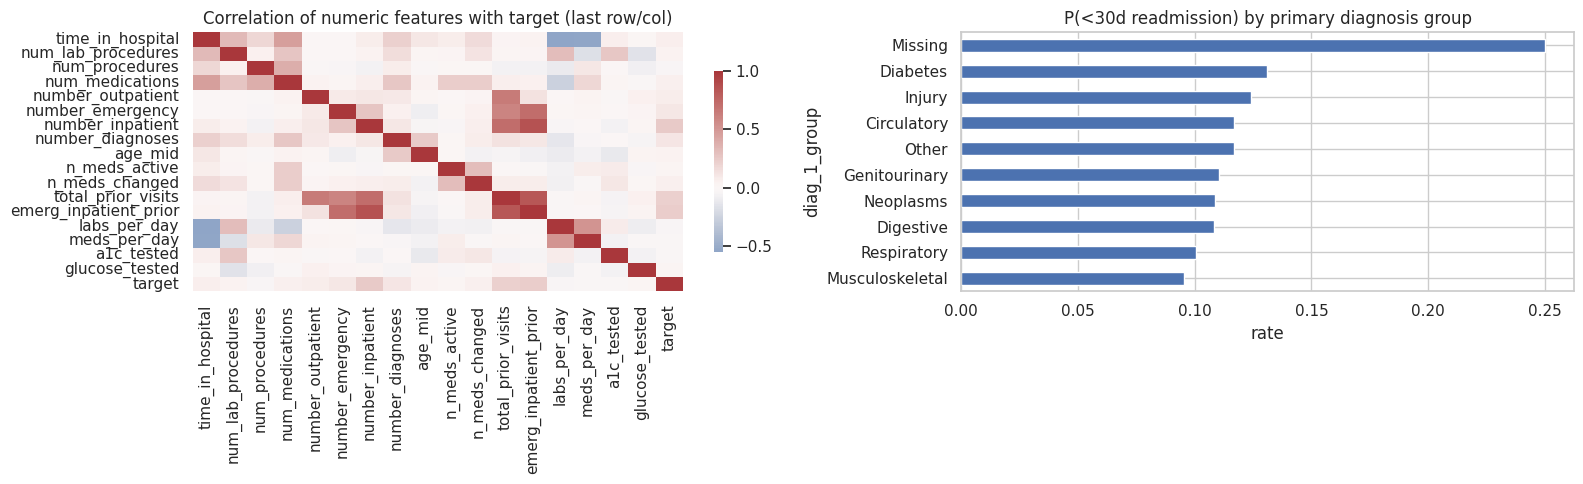

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
corr = X[NUM_COLS].assign(target=y).corr()
sns.heatmap(corr, cmap="vlag", center=0, ax=axes[0], cbar_kws={"shrink": .7})
axes[0].set_title("Correlation of numeric features with target (last row/col)")

lt30 = pd.Series((y == 2).astype(int))
pd.crosstab(X["diag_1_group"], lt30, normalize="index")[1].sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("P(<30d readmission) by primary diagnosis group"); axes[1].set_xlabel("rate")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_features.png", dpi=150); plt.show()

**Interpretation (write your own):** note which engineered features correlate with the target and which diagnosis groups carry a higher readmission rate. Expect weak correlations across the board. That is a property of this dataset (limited signal), and it explains why accuracy is a poor headline metric here.

## 4. Patient-grouped train/validation/test split

Because a patient can have many encounters, a random row-level split would place the same patient in both training and test sets. The model could then partly *memorise patients* rather than learn generalisable risk factors, which inflates performance. We therefore use `StratifiedGroupKFold` with `patient_nbr` as the group. It keeps each patient entirely inside one split while approximately preserving class proportions.

Target split is about 70% train, 10% validation, 20% test. The **validation set is used for model selection; the test set is touched only once at the end.**

In [ ]:
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
trainval_idx, test_idx = next(outer.split(X, y, groups))

inner = StratifiedGroupKFold(n_splits=8, shuffle=True, random_state=SEED)
tr_rel, va_rel = next(inner.split(X.iloc[trainval_idx], y[trainval_idx], groups[trainval_idx]))
train_idx, val_idx = trainval_idx[tr_rel], trainval_idx[va_rel]

# leakage guard: no patient may appear in more than one split
g_tr, g_va, g_te = set(groups[train_idx]), set(groups[val_idx]), set(groups[test_idx])
assert not (g_tr & g_va) and not (g_tr & g_te) and not (g_va & g_te), "Patient leakage between splits!"

X_train, y_train, grp_train = X.iloc[train_idx], y[train_idx], groups[train_idx]
X_val,   y_val,   grp_val   = X.iloc[val_idx],   y[val_idx],   groups[val_idx]
X_test,  y_test,  grp_test  = X.iloc[test_idx],  y[test_idx],  groups[test_idx]
meta_val, meta_test = meta.iloc[val_idx].reset_index(drop=True), meta.iloc[test_idx].reset_index(drop=True)

summary = pd.DataFrame({
    "rows": [len(train_idx), len(val_idx), len(test_idx)],
    "patients": [len(g_tr), len(g_va), len(g_te)],
    **{f"share {n}": [np.mean(yy == k) for yy in (y_train, y_val, y_test)] for k, n in enumerate(CLASS_NAMES)}
}, index=["train", "val", "test"]).round(3)
summary

,rows,patients,share NO,share >30,share <30
train,68675,48597,0.532,0.355,0.113
val,10286,7117,0.520,0.365,0.115
test,20379,14273,0.523,0.360,0.116


### Shared helpers: preprocessing, metrics and result registry

The preprocessing pipeline is fitted on the training set only. Numeric features are median-imputed and standardised. Categorical features are one-hot encoded, with categories seen fewer than 50 times in training collapsed into an "infrequent" bucket, which keeps the dimensionality manageable and handles unseen categories at inference time.

In [ ]:
def make_preprocessor(num_cols, cat_cols):
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
                    ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=False))])
    return ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)], remainder="drop")

def multiclass_metrics(y_true, proba):
    pred = proba.argmax(1)
    return {"accuracy": accuracy_score(y_true, pred),
            "macro_f1": f1_score(y_true, pred, average="macro"),
            "macro_recall": recall_score(y_true, pred, average="macro"),
            "recall_<30": recall_score(y_true, pred, labels=[2], average="macro"),
            "roc_auc_ovr_macro": roc_auc_score(y_true, proba, multi_class="ovr", average="macro"),
            "log_loss": log_loss(y_true, proba, labels=[0, 1, 2])}

MODELS, PRED_VAL, DL_META, DL_HIST, RESULTS = {}, {}, {}, {}, []

def register(name, paradigm, model, proba_val, **extra):
    MODELS[name], PRED_VAL[name] = model, proba_val
    RESULTS.append({"model": name, "paradigm": paradigm, **multiclass_metrics(y_val, proba_val), **extra})

def results_table():
    return pd.DataFrame(RESULTS).sort_values("roc_auc_ovr_macro", ascending=False).reset_index(drop=True)

def plot_cm(ax, y_true, pred, title):
    ConfusionMatrixDisplay.from_predictions(y_true, pred, display_labels=CLASS_NAMES, normalize="true",
                                            ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(title)

def plot_roc_ovr(ax, y_true, proba, title):
    Y = label_binarize(y_true, classes=[0, 1, 2])
    for k, n in enumerate(CLASS_NAMES):
        fpr, tpr, _ = roc_curve(Y[:, k], proba[:, k])
        ax.plot(fpr, tpr, label=f"{n} (AUC = {auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_title(title)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.legend(loc="lower right")

## 5. Two methodological experiments

### 5.1 How much does patient leakage inflate performance?
The same gradient-boosting model is evaluated on (a) a naive random row-level split and (b) our grouped split. Both use the same preprocessing. If (a) scores higher, the difference is leakage.

### 5.2 Does feature engineering help?
The same model is trained with and without the engineered features (diagnosis groups, medication counts, prior-visit totals, per-day intensity, test flags, age midpoint). Evaluation is on the validation set.

In [ ]:
def quick_hgb(num_cols, cat_cols, Xtr, ytr, Xev, yev):
    pipe = Pipeline([("prep", make_preprocessor(num_cols, cat_cols)),
                     ("clf", HistGradientBoostingClassifier(max_iter=200, random_state=SEED))])
    pipe.fit(Xtr, ytr)
    return roc_auc_score(yev, pipe.predict_proba(Xev), multi_class="ovr")

# 5.1 leakage experiment
idx = np.arange(len(X))
tr_r, te_r = train_test_split(idx, test_size=len(val_idx), stratify=y, random_state=SEED)
auc_random  = quick_hgb(NUM_COLS, CAT_COLS, X.iloc[tr_r], y[tr_r], X.iloc[te_r], y[te_r])
auc_grouped = quick_hgb(NUM_COLS, CAT_COLS, X_train, y_train, X_val, y_val)

# 5.2 feature-engineering ablation (grouped split, validation set)
ENGINEERED = ["age_mid", "n_meds_active", "n_meds_changed", "total_prior_visits", "emerg_inpatient_prior",
              "labs_per_day", "meds_per_day", "a1c_tested", "glucose_tested",
              "diag_1_group", "diag_2_group", "diag_3_group"]
base_num = [c for c in NUM_COLS if c not in ENGINEERED]
base_cat = [c for c in CAT_COLS if c not in ENGINEERED]
auc_base = quick_hgb(base_num, base_cat, X_train, y_train, X_val, y_val)

pd.DataFrame({
    "experiment": ["Random row split (leaky)", "Patient-grouped split", "Grouped split, raw features only", "Grouped split, + engineered features"],
    "macro ROC-AUC (OvR)": [auc_random, auc_grouped, auc_base, auc_grouped]}).round(4)

,experiment,macro ROC-AUC (OvR)
0,Random row split (leaky),0.6878
1,Patient-grouped split,0.6670
2,"Grouped split, raw features only",0.6679
3,"Grouped split, + engineered features",0.6670


**Interpretation (write your own):** report the gap between the random and grouped splits and explain what it means for the validity of published results on this dataset. Then report how much the engineered features add and which of them you expect to matter most. Permutation importance in Section 10 will test that expectation.

## 6. Traditional machine learning (Scikit-Learn)

**Plan**

1. A majority-prior `DummyClassifier` as a floor.
2. Default-hyperparameter baselines: Logistic Regression, Random Forest, Histogram Gradient Boosting, and an RBF-SVM on a training subsample.
3. `RandomizedSearchCV` for Logistic Regression, Random Forest and Gradient Boosting, using **3-fold `StratifiedGroupKFold` on the training set** (so tuning itself is leakage-free) and macro one-vs-rest ROC-AUC as the objective.

All models are wrapped in a `Pipeline` with the preprocessor, so scaling and encoding are re-fitted inside every CV fold.

In [ ]:
def pipe(clf):
    return Pipeline([("prep", make_preprocessor(NUM_COLS, CAT_COLS)), ("clf", clf)])

baselines = {
    "Dummy (class prior)":      DummyClassifier(strategy="prior"),
    "Logistic Regression":      LogisticRegression(max_iter=2000),
    "Random Forest":            RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
    "Hist Gradient Boosting":   HistGradientBoostingClassifier(max_iter=200, random_state=SEED),
}
for name, clf in baselines.items():
    m = pipe(clf).fit(X_train, y_train)
    register(name, "Traditional ML", m, m.predict_proba(X_val))
    print(f"{name:26s} val AUC = {RESULTS[-1]['roc_auc_ovr_macro']:.4f}")

# SVM on a stratified subsample (kernel SVMs are O(n^2) to O(n^3))
rng = np.random.RandomState(SEED)
sub = rng.choice(len(X_train), size=min(SVM_SUBSAMPLE, len(X_train)), replace=False)
svm = pipe(SVC(kernel="rbf", C=1.0, probability=True, random_state=SEED)).fit(X_train.iloc[sub], y_train[sub])
register(f"SVM (RBF, n={len(sub):,} subsample)", "Traditional ML", svm, svm.predict_proba(X_val))
print(f"{'SVM (RBF, subsample)':26s} val AUC = {RESULTS[-1]['roc_auc_ovr_macro']:.4f}")

Dummy (class prior)        val AUC = 0.5000
Logistic Regression        val AUC = 0.6626
Random Forest              val AUC = 0.6639
Hist Gradient Boosting     val AUC = 0.6670
SVM (RBF, subsample)       val AUC = 0.6432


In [ ]:
cv3 = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)

search_spaces = {
    "Logistic Regression (tuned)": (pipe(LogisticRegression(max_iter=3000)),
        {"clf__C": loguniform(1e-3, 10), "clf__class_weight": [None, "balanced"]}),
    "Random Forest (tuned)": (pipe(RandomForestClassifier(n_jobs=1, random_state=SEED)),
        {"clf__n_estimators": [200, 400], "clf__max_depth": [8, 12, 16, None],
         "clf__min_samples_leaf": [3, 5, 10, 20], "clf__max_features": ["sqrt", 0.3]}),
    "Hist Gradient Boosting (tuned)": (pipe(HistGradientBoostingClassifier(random_state=SEED)),
        {"clf__learning_rate": loguniform(0.02, 0.2), "clf__max_leaf_nodes": [15, 31, 63],
         "clf__max_iter": [150, 300], "clf__min_samples_leaf": [20, 50, 100],
         "clf__l2_regularization": loguniform(1e-3, 10), "clf__max_depth": [None, 4, 6, 8]}),
}

SEARCHES = {}
for name, (estimator, space) in search_spaces.items():
    s = RandomizedSearchCV(estimator, space, n_iter=N_ML_SEARCH_ITER, scoring="roc_auc_ovr", cv=cv3,
                           random_state=SEED, n_jobs=-1, verbose=1, refit=True)
    s.fit(X_train, y_train, groups=grp_train)
    SEARCHES[name] = s
    register(name, "Traditional ML", s.best_estimator_, s.best_estimator_.predict_proba(X_val), cv_auc=s.best_score_)
    print(f"\n{name}\n  best CV AUC = {s.best_score_:.4f} | val AUC = {RESULTS[-1]['roc_auc_ovr_macro']:.4f}\n  {s.best_params_}")

Fitting 3 folds for each of 12 candidates, totalling 36 fits

Logistic Regression (tuned)
  best CV AUC = 0.6602 | val AUC = 0.6626
  {'clf__C': np.float64(0.03148911647956861), 'clf__class_weight': None}
Fitting 3 folds for each of 12 candidates, totalling 36 fits

Random Forest (tuned)
  best CV AUC = 0.6664 | val AUC = 0.6631
  {'clf__n_estimators': 200, 'clf__min_samples_leaf': 10, 'clf__max_features': 'sqrt', 'clf__max_depth': None}
Fitting 3 folds for each of 12 candidates, totalling 36 fits

Hist Gradient Boosting (tuned)
  best CV AUC = 0.6720 | val AUC = 0.6697
  {'clf__l2_regularization': np.float64(2.1516897298083326), 'clf__learning_rate': np.float64(0.029812242770646535), 'clf__max_depth': None, 'clf__max_iter': 300, 'clf__max_leaf_nodes': 31, 'clf__min_samples_leaf': 50}


In [ ]:
# Tuning-landscape table for the best model family (document hyperparameter exploration in the report)
cvres = pd.DataFrame(SEARCHES["Hist Gradient Boosting (tuned)"].cv_results_)
cols = [c for c in cvres.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score", "rank_test_score"]
cvres[cols].sort_values("rank_test_score").head(8).round(4)

,param_clf__l2_regularization,param_clf__learning_rate,param_clf__max_depth,param_clf__max_iter,param_clf__max_leaf_nodes,param_clf__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
9,2.1517,0.0298,None,300,31,50,0.6720,0.0034,1
3,0.0053,0.0305,8,300,31,20,0.6710,0.0031,2
4,0.0534,0.0391,6,150,31,100,0.6704,0.0029,3
10,0.0502,0.0323,8,300,15,100,0.6703,0.0032,4
7,6.2451,0.1848,4,300,15,50,0.6703,0.0030,5
11,2.3396,0.0563,4,300,31,100,0.6702,0.0024,6
8,0.0025,0.0967,6,300,63,20,0.6699,0.0036,7
1,0.0042,0.0286,6,150,15,100,0.6699,0.0033,8


**Interpretation (write your own):** compare the untuned and tuned versions. Note whether tuning helped much (on weak-signal tabular data it often adds only a small gain), which model family led, and why the SVM was restricted to a subsample.

## 7. Deep learning (TensorFlow/Keras with `tf.data`)

**Inputs**

* **Dense block:** the same preprocessing as above, fitted on the training set, giving standardised numerics and one-hot categoricals.
* **ICD-9 code block (Functional model only):** the three diagnosis codes are mapped to integer IDs through a training-set vocabulary (codes seen fewer than 10 times, or missing, map to index 0) and passed through one **shared embedding layer**. The shared layer is appropriate because primary, secondary and tertiary diagnoses use the same code space. This is the "embedding vs. one-hot" comparison: the Sequential model sees only one-hot diagnosis *groups*, while the Functional model also sees embedded fine-grained codes.

**Architectures**

* `Sequential`: dense, batch-norm, dropout stacks.
* `Functional`: two named inputs, `dense` and `codes`, with an embedding branch concatenated to the dense branch.

**Pipeline:** `tf.data.Dataset.from_tensor_slices` then `shuffle`, `batch`, `prefetch`. Training uses `EarlyStopping` and `ReduceLROnPlateau` on validation loss.

**Hyperparameter exploration:** random search over depth/width, dropout, L2, learning rate, batch size and class weighting.

In [ ]:
# ---- inputs ----------------------------------------------------------------
prep_dl = make_preprocessor(NUM_COLS, CAT_COLS)
Xtr_d = prep_dl.fit_transform(X_train).astype("float32")
Xva_d = prep_dl.transform(X_val).astype("float32")
Xte_d = prep_dl.transform(X_test).astype("float32")
INPUT_DIM = Xtr_d.shape[1]

code_counts = pd.concat([X_train[c] for c in CODE_COLS]).value_counts()
vocab = [c for c, n in code_counts.items() if n >= 10 and c != "Missing"]
code2idx = {c: i + 1 for i, c in enumerate(vocab)}        # 0 = unknown / rare / missing
N_CODES = len(vocab) + 1

def encode_codes(Xdf):
    return np.stack([Xdf[c].map(code2idx).fillna(0).astype("int32").values for c in CODE_COLS], axis=1)

Ctr, Cva, Cte = encode_codes(X_train), encode_codes(X_val), encode_codes(X_test)
print(f"Dense input dim: {INPUT_DIM} | ICD vocabulary: {N_CODES} | unknown-code share (train): {(Ctr == 0).mean():.1%}")

# ---- tf.data pipeline ---------------------------------------------------------
def make_ds(dense, codes, labels, batch_size=256, training=False, use_codes=False):
    feats = {"dense_input": dense, "codes": codes} if use_codes else dense
    ds = tf.data.Dataset.from_tensor_slices((feats, labels))
    if training:
        ds = ds.shuffle(buffer_size=len(labels), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

Dense input dim: 164 | ICD vocabulary: 502 | unknown-code share (train): 1.2%


In [ ]:
def _head(x, units, dropout, l2):
    for u in units:
        x = layers.Dense(u, activation="relu", kernel_regularizer=regularizers.l2(l2))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Dropout(dropout)(x)
    return x

def _compile(model, lr, n_classes):
    loss = "binary_crossentropy" if n_classes == 2 else "sparse_categorical_crossentropy"
    model.compile(optimizer=keras.optimizers.Adam(lr), loss=loss, metrics=["accuracy"])
    return model

def build_sequential(units=(128, 64), dropout=0.3, l2=1e-4, lr=1e-3, n_classes=3, **_):
    m = keras.Sequential(name="sequential_mlp")
    m.add(keras.Input(shape=(INPUT_DIM,)))
    for u in units:
        m.add(layers.Dense(u, activation="relu", kernel_regularizer=regularizers.l2(l2)))
        m.add(layers.BatchNormalization())
        m.add(layers.Dropout(dropout))
    m.add(layers.Dense(1, activation="sigmoid") if n_classes == 2 else layers.Dense(n_classes, activation="softmax"))
    return _compile(m, lr, n_classes)

def build_functional(units=(128, 64), dropout=0.3, l2=1e-4, lr=1e-3, n_classes=3, emb_dim=16, **_):
    dense_in = keras.Input(shape=(INPUT_DIM,), name="dense_input")
    codes_in = keras.Input(shape=(len(CODE_COLS),), dtype="int32", name="codes")
    e = layers.Embedding(N_CODES, emb_dim, name="icd_embedding")(codes_in)   # shared across diag_1/2/3
    e = layers.Flatten()(e)
    x = _head(layers.Concatenate()([dense_in, e]), units, dropout, l2)
    out = layers.Dense(1, activation="sigmoid")(x) if n_classes == 2 else layers.Dense(n_classes, activation="softmax")(x)
    m = keras.Model(inputs={"dense_input": dense_in, "codes": codes_in}, outputs=out, name="functional_icd_embedding")
    return _compile(m, lr, n_classes)

BUILDERS = {"sequential": build_sequential, "functional": build_functional}

def train_dl(kind, cfg, ytr, yva, n_classes=3, epochs=40, verbose=0):
    keras.utils.set_random_seed(SEED)
    use_codes = kind == "functional"
    ds_tr = make_ds(Xtr_d, Ctr, ytr, cfg.get("batch_size", 256), True, use_codes)
    ds_va = make_ds(Xva_d, Cva, yva, 1024, False, use_codes)
    model = BUILDERS[kind](n_classes=n_classes, **cfg)
    cw = None
    if cfg.get("class_weight"):
        classes = np.unique(ytr)
        cw = dict(zip(classes, compute_class_weight("balanced", classes=classes, y=ytr)))
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)]
    hist = model.fit(ds_tr, validation_data=ds_va, epochs=epochs, callbacks=cbs, class_weight=cw, verbose=verbose)
    proba = model.predict(ds_va, verbose=0)
    return model, hist, (proba.ravel() if n_classes == 2 else proba)

keras.utils.set_random_seed(SEED)
build_functional().summary()

Model: "functional_icd_embedding"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ codes (InputLayer)  │ (None, 3)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ icd_embedding       │ (None, 3, 16)     │      8,032 │ codes[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_input         │ (None, 164)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 48)        │          0 │ icd_embedding[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 212)       │          0 │ dense_input[0][0… │
│ (Concatenate)       │                   │            │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 128)       │     27,264 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_3[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64)        │      8,256 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_4[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 3)         │        195 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 44,515 (173.89 KB)

 Trainable params: 44,131 (172.39 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
DL_GRID = {"units": [(64,), (128, 64), (256, 128, 64)],
           "dropout": [0.2, 0.3, 0.5],
           "l2": [1e-5, 1e-4, 1e-3],
           "lr": [1e-3, 3e-4],
           "batch_size": [128, 256, 512],
           "class_weight": [False, True]}

sweep_rows, DL_BEST = [], {}
for kind in ["sequential", "functional"]:
    best = None
    for cfg in ParameterSampler(DL_GRID, n_iter=N_DL_TRIALS, random_state=SEED):
        model, hist, proba = train_dl(kind, cfg, y_train, y_val)
        v_auc = roc_auc_score(y_val, proba, multi_class="ovr")
        sweep_rows.append({"kind": kind, **cfg, "epochs": len(hist.history["loss"]),
                           "val_loss": min(hist.history["val_loss"]), "val_auc": v_auc})
        print(f"[{kind}] val AUC={v_auc:.4f} | {cfg}")
        if best is None or v_auc > best["auc"]:
            best = {"auc": v_auc, "cfg": cfg, "model": model, "hist": hist, "proba": proba}
    DL_BEST[kind] = best
    name = {"sequential": "Keras Sequential (tuned)", "functional": "Keras Functional + ICD embedding (tuned)"}[kind]
    register(name, "Deep Learning", best["model"], best["proba"])
    DL_META[name], DL_HIST[name] = kind, best["hist"].history

sweep = pd.DataFrame(sweep_rows).sort_values(["kind", "val_auc"], ascending=[True, False])
sweep.round(4)

[sequential] val AUC=0.6724 | {'units': (64,), 'lr': 0.001, 'l2': 0.0001, 'dropout': 0.3, 'class_weight': False, 'batch_size': 256}
[sequential] val AUC=0.6688 | {'units': (64,), 'lr': 0.001, 'l2': 1e-05, 'dropout': 0.2, 'class_weight': False, 'batch_size': 256}
[sequential] val AUC=0.6721 | {'units': (256, 128, 64), 'lr': 0.0003, 'l2': 0.0001, 'dropout': 0.3, 'class_weight': False, 'batch_size': 256}
[sequential] val AUC=0.6677 | {'units': (64,), 'lr': 0.0003, 'l2': 0.0001, 'dropout': 0.2, 'class_weight': False, 'batch_size': 128}
[sequential] val AUC=0.6610 | {'units': (64,), 'lr': 0.001, 'l2': 1e-05, 'dropout': 0.3, 'class_weight': True, 'batch_size': 256}
[sequential] val AUC=0.6715 | {'units': (64,), 'lr': 0.001, 'l2': 1e-05, 'dropout': 0.3, 'class_weight': False, 'batch_size': 256}
[sequential] val AUC=0.6668 | {'units': (64,), 'lr': 0.0003, 'l2': 1e-05, 'dropout': 0.2, 'class_weight': False, 'batch_size': 512}
[sequential] val AUC=0.6598 | {'units': (128, 64), 'lr': 0.0003, 'l2'

,kind,units,lr,l2,dropout,class_weight,batch_size,epochs,val_loss,val_auc
10,functional,"(256, 128, 64)",0.0003,0.0001,0.3,False,256,24,0.9178,0.6768
11,functional,"(64,)",0.0003,0.0001,0.2,False,128,13,0.8951,0.6757
9,functional,"(64,)",0.0010,0.0000,0.2,False,256,12,0.8887,0.6743
14,functional,"(64,)",0.0003,0.0000,0.2,False,512,29,0.8902,0.6741
13,functional,"(64,)",0.0010,0.0000,0.3,False,256,12,0.8891,0.6731
8,functional,"(64,)",0.0010,0.0001,0.3,False,256,16,0.8960,0.6721
15,functional,"(128, 64)",0.0003,0.0010,0.3,True,256,32,1.0439,0.6647
12,functional,"(64,)",0.0010,0.0000,0.3,True,256,19,1.0126,0.6582
0,sequential,"(64,)",0.0010,0.0001,0.3,False,256,24,0.8944,0.6724
2,sequential,"(256, 128, 64)",0.0003,0.0001,0.3,False,256,30,0.9174,0.6721


**Interpretation (write your own):** discuss which hyperparameters mattered (for example, did class weighting trade accuracy for minority-class recall? Did heavier regularisation help?), whether the embedding branch of the Functional model helped over the Sequential model, and the gap between training and validation loss in the learning curves (Section 8).

## 8. Evaluation

### 8.1 Validation leaderboard
All models, ranked by macro one-vs-rest ROC-AUC on the validation set. `recall_<30` is the recall of the clinically most important class.

In [ ]:
leaderboard = results_table()
leaderboard.round(4)

,model,paradigm,accuracy,macro_f1,macro_recall,recall_<30,roc_auc_ovr_macro,log_loss,cv_auc
0,Keras Functional + ICD embedding (tuned),Deep Learning,0.5793,0.4064,0.4244,0.0202,0.6768,0.8855,NaN
1,Keras Sequential (tuned),Deep Learning,0.5780,0.3978,0.4171,0.0202,0.6724,0.8891,NaN
2,Hist Gradient Boosting (tuned),Traditional ML,0.5783,0.3992,0.4175,0.0244,0.6697,0.8904,0.6720
3,Hist Gradient Boosting,Traditional ML,0.5790,0.4043,0.4202,0.0320,0.6670,0.8920,NaN
4,Random Forest,Traditional ML,0.5776,0.3818,0.4092,0.0017,0.6639,0.8958,NaN
5,Random Forest (tuned),Traditional ML,0.5754,0.3788,0.4069,0.0000,0.6631,0.8971,0.6664
6,Logistic Regression (tuned),Traditional ML,0.5740,0.3830,0.4065,0.0202,0.6626,0.9005,0.6602
7,Logistic Regression,Traditional ML,0.5741,0.3862,0.4080,0.0253,0.6626,0.9004,NaN
8,"SVM (RBF, n=15,000 subsample)",Traditional ML,0.5701,0.3707,0.3999,0.0034,0.6432,0.9116,NaN
9,Dummy (class prior),Traditional ML,0.5198,0.2280,0.3333,0.0000,0.5000,0.9574,NaN


In [ ]:
res = results_table()
best_ml_name = res[res.paradigm == "Traditional ML"].iloc[0]["model"]
best_dl_name = res[res.paradigm == "Deep Learning"].iloc[0]["model"]
print("Best traditional ML:", best_ml_name)
print("Best deep learning :", best_dl_name)

Best traditional ML: Hist Gradient Boosting (tuned)
Best deep learning : Keras Functional + ICD embedding (tuned)


### 8.2 Learning curves

* **Traditional ML:** training-size learning curve for the best sklearn model (grouped 3-fold CV, so the validation score is leakage-free).
* **Deep learning:** per-epoch loss and accuracy for both tuned Keras models.

A large, persistent gap between training and validation curves indicates variance (overfitting). Two curves that plateau together at a modest score indicate high bias or limited signal in the features.

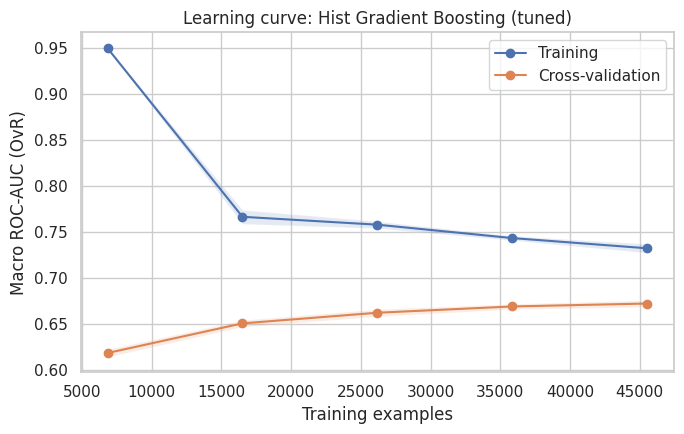

In [ ]:
sizes, tr_sc, va_sc = learning_curve(MODELS[best_ml_name], X_train, y_train, groups=grp_train, cv=cv3,
                                     train_sizes=np.linspace(0.15, 1.0, 5), scoring="roc_auc_ovr", n_jobs=-1)
fig, ax = plt.subplots(figsize=(7, 4.5))
for sc, lab in [(tr_sc, "Training"), (va_sc, "Cross-validation")]:
    ax.plot(sizes, sc.mean(1), "o-", label=lab)
    ax.fill_between(sizes, sc.mean(1) - sc.std(1), sc.mean(1) + sc.std(1), alpha=0.15)
ax.set_xlabel("Training examples"); ax.set_ylabel("Macro ROC-AUC (OvR)"); ax.set_title(f"Learning curve: {best_ml_name}")
ax.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "learning_curve_ml.png", dpi=150); plt.show()

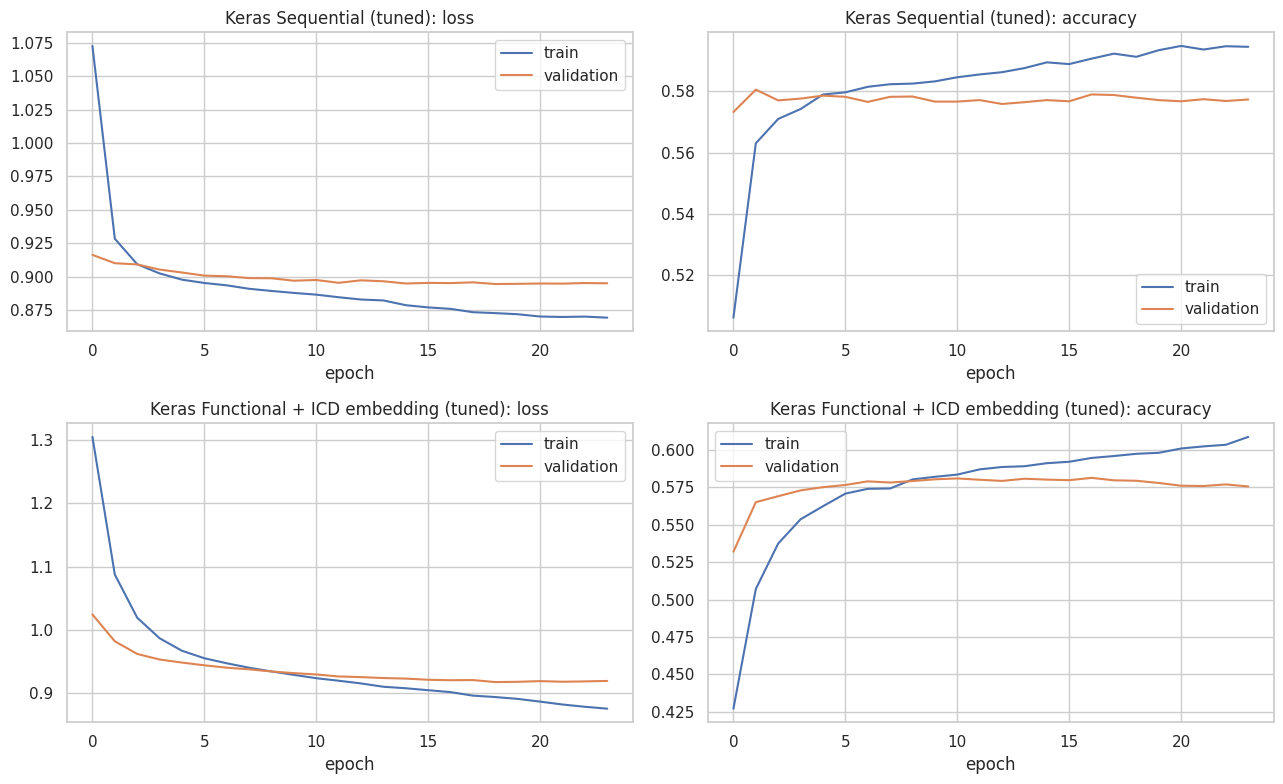

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for r, name in enumerate(DL_HIST):
    h = DL_HIST[name]
    axes[r, 0].plot(h["loss"], label="train"); axes[r, 0].plot(h["val_loss"], label="validation")
    axes[r, 0].set_title(f"{name}: loss"); axes[r, 0].set_xlabel("epoch"); axes[r, 0].legend()
    axes[r, 1].plot(h["accuracy"], label="train"); axes[r, 1].plot(h["val_accuracy"], label="validation")
    axes[r, 1].set_title(f"{name}: accuracy"); axes[r, 1].set_xlabel("epoch"); axes[r, 1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "learning_curves_dl.png", dpi=150); plt.show()

### 8.3 Confusion matrices and ROC curves (validation set)
Confusion matrices are row-normalised (each row shows what fraction of a true class is predicted as each class, so the diagonal is per-class recall).

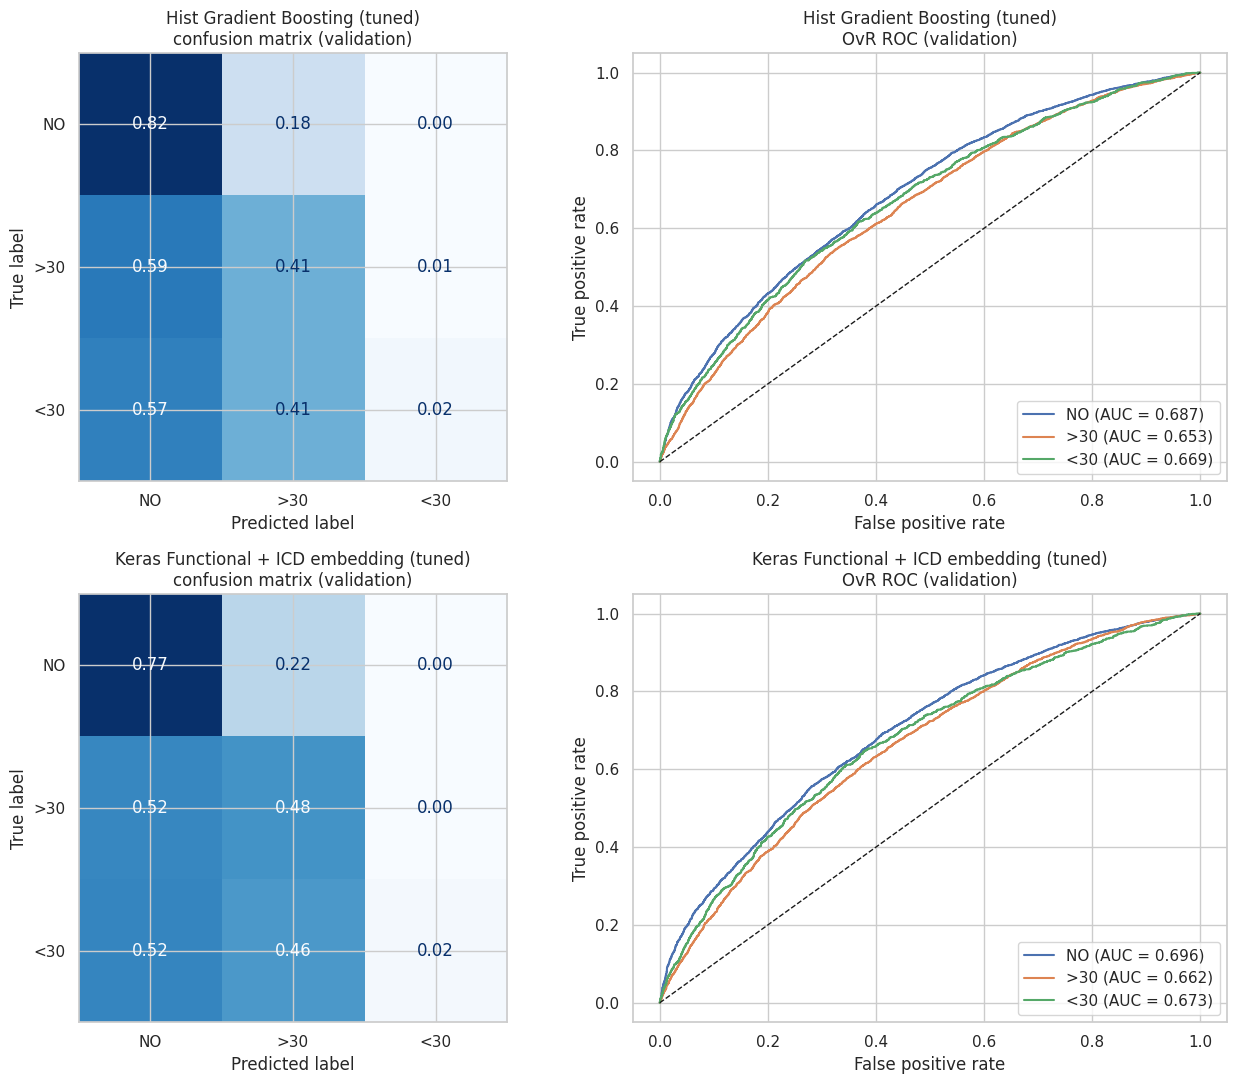

              precision    recall  f1-score   support

          NO      0.604     0.822     0.696      5347
         >30      0.517     0.406     0.455      3752
         <30      0.500     0.024     0.047      1187

    accuracy                          0.578     10286
   macro avg      0.540     0.417     0.399     10286
weighted avg      0.560     0.578     0.533     10286



In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for r, name in enumerate([best_ml_name, best_dl_name]):
    p = PRED_VAL[name]
    plot_cm(axes[r, 0], y_val, p.argmax(1), f"{name}\nconfusion matrix (validation)")
    plot_roc_ovr(axes[r, 1], y_val, p, f"{name}\nOvR ROC (validation)")
plt.tight_layout(); plt.savefig(FIG_DIR / "cm_roc_validation.png", dpi=150); plt.show()

print(classification_report(y_val, PRED_VAL[best_ml_name].argmax(1), target_names=CLASS_NAMES, digits=3))

### 8.4 Final, one-time test-set evaluation
The best traditional model and the best deep model (chosen on validation) are evaluated on the held-out test set **once**. The Dummy model is included as a floor.

In [ ]:
def predict_test(name):
    if name in DL_META:
        kind = DL_META[name]
        ds = make_ds(Xte_d, Cte, y_test, 1024, False, kind == "functional")
        return MODELS[name].predict(ds, verbose=0)
    return MODELS[name].predict_proba(X_test)

PRED_TEST = {n: predict_test(n) for n in ["Dummy (class prior)", best_ml_name, best_dl_name]}
test_table = pd.DataFrame([{"model": n, **multiclass_metrics(y_test, p)} for n, p in PRED_TEST.items()])
test_table.round(4)

,model,accuracy,macro_f1,macro_recall,recall_<30,roc_auc_ovr_macro,log_loss
0,Dummy (class prior),0.5232,0.2290,0.3333,0.0000,0.5000,0.9573
1,Hist Gradient Boosting (tuned),0.5813,0.4039,0.4200,0.0333,0.6792,0.8825
2,Keras Functional + ICD embedding (tuned),0.5842,0.4115,0.4279,0.0265,0.6822,0.8805


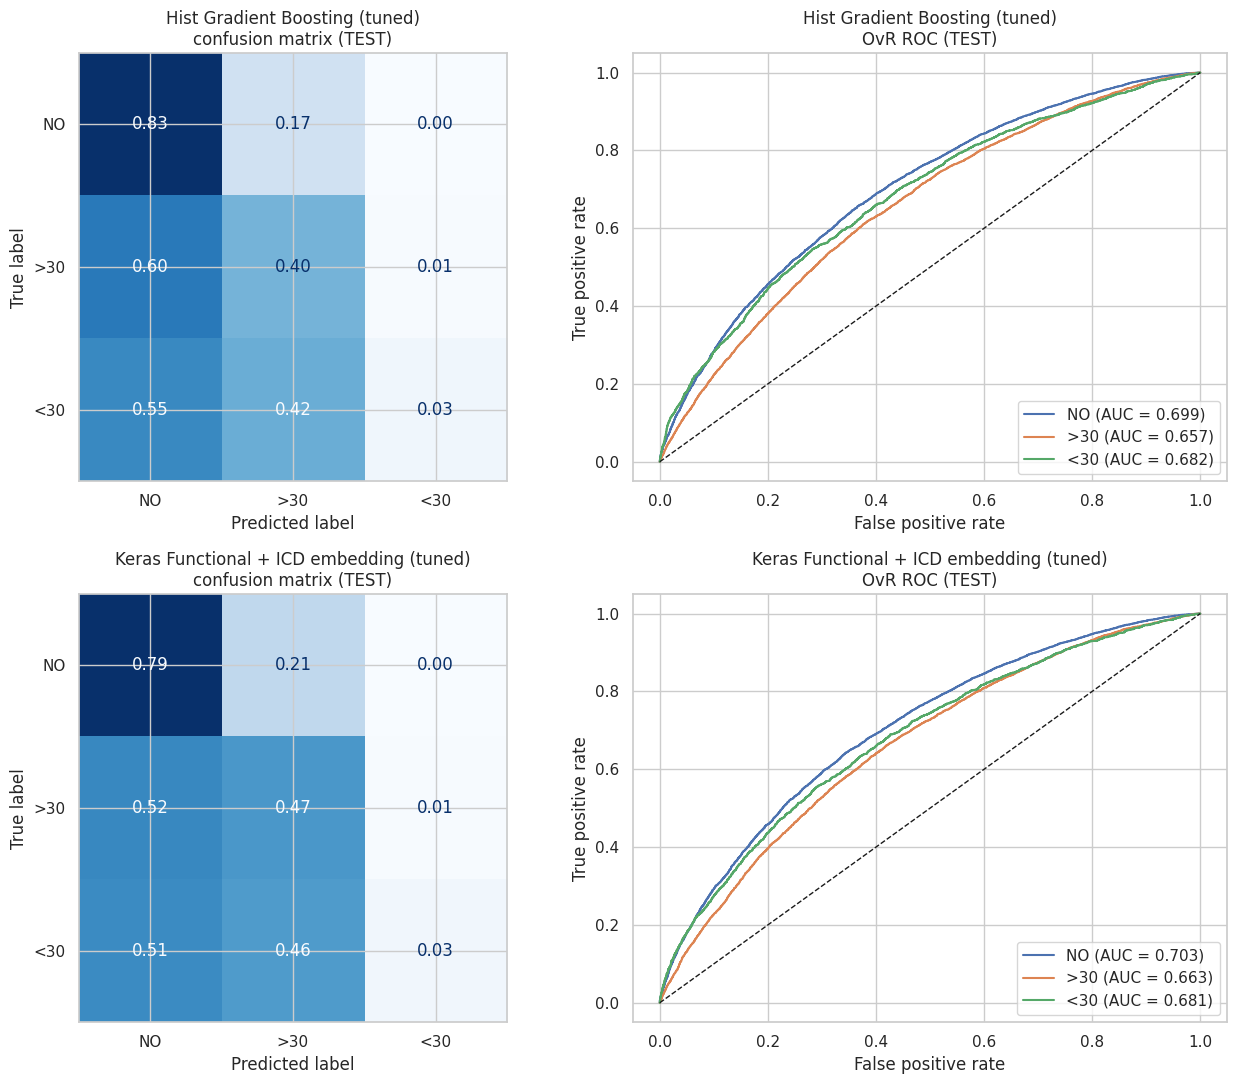

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for r, name in enumerate([best_ml_name, best_dl_name]):
    plot_cm(axes[r, 0], y_test, PRED_TEST[name].argmax(1), f"{name}\nconfusion matrix (TEST)")
    plot_roc_ovr(axes[r, 1], y_test, PRED_TEST[name], f"{name}\nOvR ROC (TEST)")
plt.tight_layout(); plt.savefig(FIG_DIR / "cm_roc_test.png", dpi=150); plt.show()

**Interpretation (write your own):** report the final comparison table. Does gradient boosting match or beat the neural network? Explain why that is plausible on structured data of this size (tree ensembles handle mixed-type features and interactions with little tuning, while neural networks need more data and careful regularisation to match them). Comment on the low recall for `<30` and the heavy confusion between `NO` and `>30`.

## 9. Clinically motivated follow-up: `<30`-day readmission vs. rest

Hospitals and payers mostly care about the 30-day readmission flag. This is a binary problem with roughly 11% positives, so accuracy is misleading. We report ROC-AUC, **PR-AUC (average precision)**, and precision/recall/F1 at a decision threshold chosen on the validation set (the threshold maximising validation F1) and then applied unchanged to the test set. Class imbalance is handled through balanced sample weights (sklearn) and class weights (Keras).

In [ ]:
yb_train, yb_val, yb_test = [(a == 2).astype(int) for a in (y_train, y_val, y_test)]
print(f"Positive rate: train {yb_train.mean():.3f} | val {yb_val.mean():.3f} | test {yb_test.mean():.3f}")

def best_f1_threshold(y_true, score):
    p, r, t = precision_recall_curve(y_true, score)
    f1 = 2 * p * r / (p + r + 1e-12)
    return t[np.argmax(f1[:-1])]

def bin_metrics(name, y_true, score, thr):
    pred = (score >= thr).astype(int)
    return {"model": name, "roc_auc": roc_auc_score(y_true, score), "pr_auc": average_precision_score(y_true, score),
            "precision": precision_score(y_true, pred, zero_division=0), "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred), "threshold": thr}

hgb_params = {k.replace("clf__", ""): v for k, v in SEARCHES["Hist Gradient Boosting (tuned)"].best_params_.items()}
w_train = compute_sample_weight("balanced", yb_train)

bin_models = {
    "Logistic Regression (balanced)": pipe(LogisticRegression(max_iter=3000, C=0.1)),
    "Hist Gradient Boosting (balanced)": pipe(HistGradientBoostingClassifier(random_state=SEED, **hgb_params)),
}
bin_val, bin_test, bin_rows = {}, {}, []
for name, m in bin_models.items():
    m.fit(X_train, yb_train, clf__sample_weight=w_train)
    bin_val[name], bin_test[name] = m.predict_proba(X_val)[:, 1], m.predict_proba(X_test)[:, 1]

# Keras functional model, binary head, class-weighted
cfg_bin = {**DL_BEST["functional"]["cfg"], "class_weight": True}
dl_bin, dl_hist, dl_val_score = train_dl("functional", cfg_bin, yb_train, yb_val, n_classes=2)
bin_val["Keras Functional (class-weighted)"] = dl_val_score
bin_test["Keras Functional (class-weighted)"] = dl_bin.predict(
    make_ds(Xte_d, Cte, yb_test, 1024, False, True), verbose=0).ravel()

for name in bin_val:
    thr = best_f1_threshold(yb_val, bin_val[name])
    bin_rows.append(bin_metrics(name, yb_test, bin_test[name], thr))
bin_table = pd.DataFrame(bin_rows).sort_values("pr_auc", ascending=False)
print("TEST-set metrics (threshold tuned on validation):")
bin_table.round(4)

Positive rate: train 0.113 | val 0.115 | test 0.116
TEST-set metrics (threshold tuned on validation):


,model,roc_auc,pr_auc,precision,recall,f1,threshold
1,Hist Gradient Boosting (balanced),0.6818,0.2379,0.2301,0.4458,0.3035,0.5613
0,Logistic Regression (balanced),0.6701,0.2248,0.2018,0.4657,0.2816,0.5325
2,Keras Functional (class-weighted),0.6189,0.1881,0.1601,0.5145,0.2442,0.4778


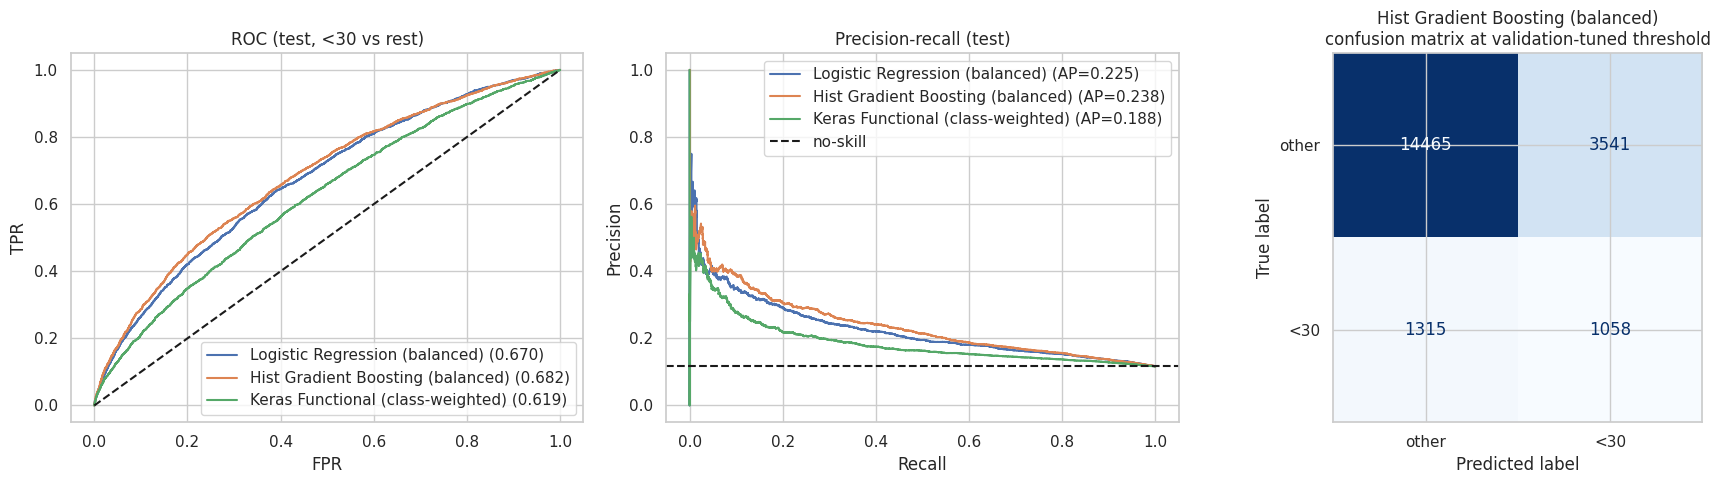

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for name, s in bin_test.items():
    fpr, tpr, _ = roc_curve(yb_test, s); axes[0].plot(fpr, tpr, label=f"{name} ({auc(fpr, tpr):.3f})")
    p, r, _ = precision_recall_curve(yb_test, s); axes[1].plot(r, p, label=f"{name} (AP={average_precision_score(yb_test, s):.3f})")
axes[0].plot([0, 1], [0, 1], "k--"); axes[0].set_title("ROC (test, <30 vs rest)"); axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR"); axes[0].legend()
axes[1].axhline(yb_test.mean(), color="k", ls="--", label="no-skill"); axes[1].set_title("Precision-recall (test)")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].legend()

top_name = bin_table.iloc[0]["model"]
thr = bin_table.iloc[0]["threshold"]
ConfusionMatrixDisplay.from_predictions(yb_test, (bin_test[top_name] >= thr).astype(int), display_labels=["other", "<30"],
                                        ax=axes[2], cmap="Blues", colorbar=False)
axes[2].set_title(f"{top_name}\nconfusion matrix at validation-tuned threshold")
plt.tight_layout(); plt.savefig(FIG_DIR / "binary_followup.png", dpi=150); plt.show()

**Interpretation (write your own):** relate the PR curve to the no-skill baseline (the positive rate). Explain the precision/recall trade-off at the chosen threshold in clinical terms: how many extra patients would be flagged to catch a given share of true 30-day readmissions, and what an intervention programme could afford.

## 10. Error analysis and fairness

This section supports the "critical error analysis" criterion. We look at (i) which features drive the best model, (ii) how confident its mistakes are, and (iii) whether performance differs across age and race groups.

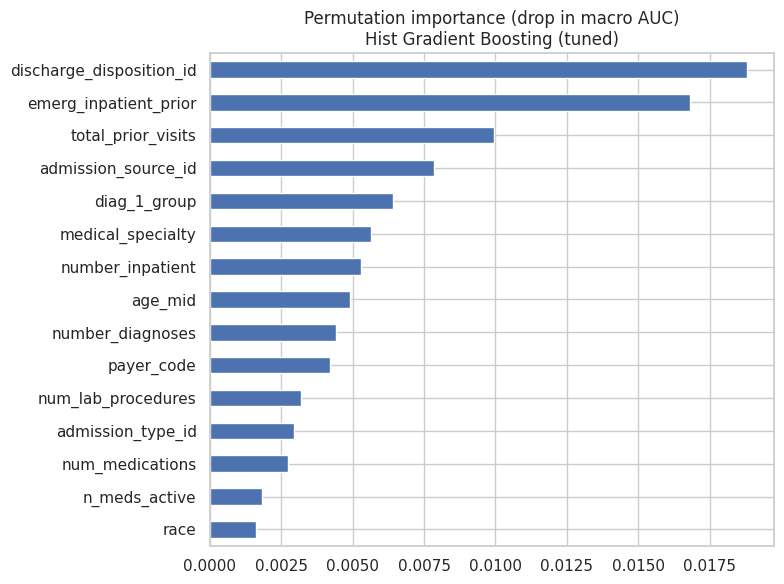

In [ ]:
# (i) permutation importance on a validation subsample (works on raw columns thanks to the Pipeline)
sub_idx = np.random.RandomState(SEED).choice(len(X_val), size=min(5000, len(X_val)), replace=False)
pi = permutation_importance(MODELS[best_ml_name], X_val.iloc[sub_idx], y_val[sub_idx], scoring="roc_auc_ovr",
                            n_repeats=3, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_val.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 6))
imp.head(15).iloc[::-1].plot(kind="barh", ax=ax)
ax.set_title(f"Permutation importance (drop in macro AUC)\n{best_ml_name}"); plt.tight_layout()
plt.savefig(FIG_DIR / "permutation_importance.png", dpi=150); plt.show()

           count   mean    std    min    25%    50%    75%    max
correct                                                          
False     8532.0  0.551  0.094  0.345  0.480  0.531  0.608  0.884
True     11847.0  0.600  0.110  0.337  0.509  0.586  0.682  0.914 

Most common confusions (true -> predicted):
           count
true pred       
>30  NO     4391
NO   >30    1768
<30  NO     1299
     >30     995
>30  <30      50
NO   <30      29


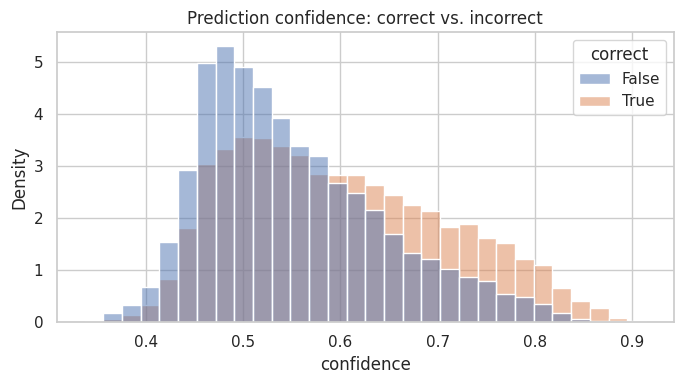

In [ ]:
# (ii) how do the errors look? Use the best model on the test set
p = PRED_TEST[best_ml_name]; pred = p.argmax(1); conf = p.max(1)
err = pd.DataFrame({"true": [CLASS_NAMES[i] for i in y_test], "pred": [CLASS_NAMES[i] for i in pred],
                    "confidence": conf, "correct": pred == y_test})
print(err.groupby("correct")["confidence"].describe().round(3), "\n")
print("Most common confusions (true -> predicted):")
print(err[~err.correct].groupby(["true", "pred"]).size().sort_values(ascending=False).to_frame("count"))

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=err, x="confidence", hue="correct", bins=30, stat="density", common_norm=False, ax=ax)
ax.set_title("Prediction confidence: correct vs. incorrect"); plt.tight_layout(); plt.show()

In [ ]:
# (iii) subgroup analysis by age band and race on the test set (<30 vs. rest risk score = P(<30))
def subgroup_report(col, min_n=300):
    rows = []
    for g, idx in meta_test.groupby(col).groups.items():
        idx = np.array(idx)
        if len(idx) < min_n: continue
        yt, pp = y_test[idx], p[idx]
        row = {col: g, "n": len(idx), "accuracy": accuracy_score(yt, pp.argmax(1)),
               "actual <30 rate": (yt == 2).mean(), "mean P(<30)": pp[:, 2].mean(),
               "recall <30": recall_score(yt == 2, pp.argmax(1) == 2, zero_division=0)}
        row["AUC <30 vs rest"] = roc_auc_score(yt == 2, pp[:, 2]) if 0 < (yt == 2).sum() < len(yt) else np.nan
        rows.append(row)
    return pd.DataFrame(rows).sort_values(col).round(3)

display(subgroup_report("age"))
display(subgroup_report("race"))
display(subgroup_report("gender"))

,age,n,accuracy,actual <30 rate,mean P(<30),recall <30,AUC <30 vs rest
0,[20-30),308,0.633,0.143,0.113,0.136,0.742
1,[30-40),756,0.615,0.116,0.102,0.023,0.705
2,[40-50),2003,0.636,0.097,0.107,0.036,0.716
3,[50-60),3574,0.608,0.098,0.104,0.057,0.711
4,[60-70),4490,0.580,0.122,0.112,0.031,0.669
5,[70-80),5226,0.553,0.125,0.120,0.028,0.663
6,[80-90),3377,0.547,0.127,0.125,0.019,0.657
7,[90-100),506,0.595,0.117,0.117,0.017,0.609


,race,n,accuracy,actual <30 rate,mean P(<30),recall <30,AUC <30 vs rest
0,AfricanAmerican,3791,0.573,0.115,0.114,0.032,0.683
1,Caucasian,15246,0.578,0.117,0.115,0.034,0.681
2,Hispanic,433,0.584,0.143,0.110,0.065,0.763
3,Other,349,0.642,0.115,0.100,0.000,0.641
4,Unknown,430,0.672,0.098,0.088,0.024,0.613


,gender,n,accuracy,actual <30 rate,mean P(<30),recall <30,AUC <30 vs rest
0,Female,10958,0.580,0.115,0.114,0.026,0.680
1,Male,9421,0.583,0.119,0.114,0.041,0.683


**Interpretation (write your own).** Suggested points:

* **Confusions.** `>30` vs `NO` cannot be separated well because the 30-day boundary is arbitrary and clinically weak. A patient readmitted on day 31 looks almost identical to one readmitted on day 29.
* **Confidence.** If errors are made with confidence similar to correct predictions, the probabilities are not very informative, and calibration would be worth studying.
* **Fairness.** Differences in AUC or recall across age or race groups, and small subgroup sizes, bear on whether a deployed model would serve all patients equally. Note that race is an input here. Discuss whether it should be.
* **Dataset limitations.** 1999-2008 data from 130 hospitals, no outpatient follow-up or social-determinant information, readmission to a different hospital not captured, and several encounters per patient.
* **Ethics.** Who gets flagged, and what happens to flagged patients? A model that withholds care from "high-risk" patients would be harmful, whereas one that triggers extra follow-up support is not.

_Optional extension:_ run SHAP (`pip install shap`) on the best gradient-boosting model for per-prediction explanations.

## 11. Saving artifacts

The deliverables require the best traditional model (`.joblib`) and the best deep model (`.keras`). We also save the deep model's preprocessing objects (fitted scaler/encoder and the ICD vocabulary), because the network is useless at inference time without them, along with the result tables. **Upload the contents of `models/` to your Google Drive folder, and do not commit them or the raw data to GitHub.**

In [ ]:
joblib.dump(MODELS[best_ml_name], MODEL_DIR / "best_ml_pipeline.joblib")
MODELS[best_dl_name].save(MODEL_DIR / "best_dl_model.keras")
joblib.dump({"preprocessor": prep_dl, "code2idx": code2idx, "code_cols": CODE_COLS, "kind": DL_META[best_dl_name],
             "num_cols": NUM_COLS, "cat_cols": CAT_COLS, "class_names": CLASS_NAMES}, MODEL_DIR / "dl_preprocessing.joblib")
results_table().to_csv(MODEL_DIR / "validation_leaderboard.csv", index=False)
test_table.to_csv(MODEL_DIR / "test_results.csv", index=False)
sweep.to_csv(MODEL_DIR / "dl_hyperparameter_sweep.csv", index=False)

# reload check: saved artifacts must reproduce the test predictions
ml_re = joblib.load(MODEL_DIR / "best_ml_pipeline.joblib")
dl_re = keras.models.load_model(MODEL_DIR / "best_dl_model.keras")
ok_ml = np.allclose(ml_re.predict_proba(X_test), PRED_TEST[best_ml_name], atol=1e-6)
print("ML reload reproduces test predictions:", ok_ml)
ds_chk = make_ds(Xte_d, Cte, y_test, 1024, False, DL_META[best_dl_name] == "functional")
print("DL reload reproduces test predictions:", np.allclose(dl_re.predict(ds_chk, verbose=0), PRED_TEST[best_dl_name], atol=1e-4))
print(sorted(p.name for p in MODEL_DIR.iterdir()))

ML reload reproduces test predictions: True
DL reload reproduces test predictions: True
['best_dl_model.keras', 'best_ml_pipeline.joblib', 'dl_hyperparameter_sweep.csv', 'dl_preprocessing.joblib', 'test_results.csv', 'validation_leaderboard.csv']


## 12. Summary checklist before submission

* Fill in all three links at the top (GitHub, Drive, video) and repeat them on page one of the report.
* Replace each "Interpretation (write your own)" cell with your own analysis, since graders look for interpretation of outputs.
* Re-run the notebook top to bottom (`Restart & Run All`) and confirm the numbers in the report match.
* Zip `data/` into the Drive folder along with the files in `models/`. Do not commit `data/` or `models/` to GitHub.
* Pin your library versions in `requirements.txt` (`pip freeze | grep -E "tensorflow|scikit-learn|pandas|numpy"`).

**Reference for the dataset:** B. Strack et al., "Impact of HbA1c measurement on hospital readmission rates: Analysis of 70,000 clinical database patient records," *BioMed Research International*, 2014.